In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Зареждане
df = pd.read_csv(
    "data/traffic_preprocessed.csv",
    parse_dates=["date"],
    low_memory=False
)

print(f"Редове  : {len(df):,}")
print(f"Колони  : {list(df.columns)}")
print(f"Период  : {df['date'].min()}  →  {df['date'].max()}")

Редове  : 11,245,044
Колони  : ['date', 'direction', 'plate', 'country', 'speed', 'vehicle_class', 'lane', 'length', 'weight']
Период  : 2022-01-01 00:00:18  →  2024-12-31 23:59:06


In [2]:
print("=" * 60)
print("АГРЕГИРАНЕ — 1 ЧАС ПО ПОСОКА")
print("=" * 60)

# Агрегиране по час и посока
df["hour_ts"] = df["date"].dt.floor("h")

hourly = (df.groupby(["hour_ts", "direction"])
           .agg(
               volume    = ("speed", "size"),
               avg_speed = ("speed", "mean")
           )
           .reset_index()
           .rename(columns={"hour_ts": "datetime"}))

hourly["avg_speed"] = hourly["avg_speed"].round(2)

print(f"Редове след агрегиране: {len(hourly):,}")
print(f"Колони: {list(hourly.columns)}")
print(f"\nПример:")
print(hourly.head(10).to_string(index=False))

print(f"\nПо посока:")
print(hourly["direction"].value_counts().to_string())

print(f"\nОписателна статистика:")
print(hourly[["volume", "avg_speed"]].describe().round(2).to_string())

АГРЕГИРАНЕ — 1 ЧАС ПО ПОСОКА
Редове след агрегиране: 35,983
Колони: ['datetime', 'direction', 'volume', 'avg_speed']

Пример:
           datetime    direction  volume  avg_speed
2022-01-01 00:00:00 Околовръстно     143      47.30
2022-01-01 00:00:00       Център     149      53.89
2022-01-01 01:00:00 Околовръстно     174      47.68
2022-01-01 01:00:00       Център     255      53.18
2022-01-01 02:00:00 Околовръстно     195      47.33
2022-01-01 02:00:00       Център     250      52.81
2022-01-01 03:00:00 Околовръстно     178      48.07
2022-01-01 03:00:00       Център     256      53.05
2022-01-01 04:00:00 Околовръстно     160      47.29
2022-01-01 04:00:00       Център     244      51.56

По посока:
direction
Център          18114
Околовръстно    17869

Описателна статистика:
         volume  avg_speed
count  35983.00   35983.00
mean     312.51      48.63
std      333.99       4.57
min        1.00       5.00
25%       49.00      45.46
50%      142.00      49.03
75%      653.00      51

In [3]:
print("=" * 60)
print("ПРОВЕРКА НА ВИСОКИ avg_speed СТОЙНОСТИ")
print("=" * 60)

# Часове с avg_speed > 80 km/h
high_speed = hourly[hourly["avg_speed"] > 80].sort_values("avg_speed", ascending=False)
print(f"Часове с avg_speed > 80 km/h: {len(high_speed):,}")
print(high_speed.to_string(index=False))

# Колко записа има в тези часове?
print(f"\nОбем на трафика при високи средни скорости:")
print(high_speed[["datetime", "direction", "volume", "avg_speed"]].to_string(index=False))

ПРОВЕРКА НА ВИСОКИ avg_speed СТОЙНОСТИ
Часове с avg_speed > 80 km/h: 11
           datetime    direction  volume  avg_speed
2022-08-24 04:00:00       Център      11     106.18
2024-05-06 02:00:00       Център      16     100.44
2024-03-28 02:00:00       Център      34      97.44
2023-07-29 03:00:00       Център       8      92.75
2024-01-19 21:00:00       Център       1      88.00
2024-01-21 08:00:00       Център       1      88.00
2024-01-19 20:00:00       Център       1      88.00
2024-03-11 03:00:00       Център      21      87.38
2024-05-20 01:00:00       Център      34      84.79
2022-07-16 02:00:00 Околовръстно       1      83.00
2022-03-16 03:00:00       Център       6      83.00

Обем на трафика при високи средни скорости:
           datetime    direction  volume  avg_speed
2022-08-24 04:00:00       Център      11     106.18
2024-05-06 02:00:00       Център      16     100.44
2024-03-28 02:00:00       Център      34      97.44
2023-07-29 03:00:00       Център       8      92.75

In [4]:
print("=" * 60)
print("ПРАГ ЗА МИНИМАЛЕН VOLUME")
print("=" * 60)

# Часове с volume < 5 -> avg_speed = NaN
low_volume = (hourly["volume"] < 5).sum()
print(f"Часове с volume < 5: {low_volume:,}")

hourly.loc[hourly["volume"] < 5, "avg_speed"] = np.nan

print(f"avg_speed NaN след прага: {hourly['avg_speed'].isnull().sum():,}")
print(f"\nМаксимална avg_speed след прага: {hourly['avg_speed'].max():.2f}")
print(f"Описателна статистика avg_speed:")
print(hourly["avg_speed"].describe().round(2).to_string())

ПРАГ ЗА МИНИМАЛЕН VOLUME
Часове с volume < 5: 1,338
avg_speed NaN след прага: 1,338

Максимална avg_speed след прага: 106.18
Описателна статистика avg_speed:
count    34645.00
mean        48.65
std          4.24
min         10.82
25%         45.48
50%         49.03
75%         51.68
max        106.18


In [5]:
print("=" * 60)
print("ПРЕГЛЕД НА РАЗПРЕДЕЛЕНИЕТО НА VOLUME")
print("=" * 60)

print("Часове с avg_speed > 80 след прага:")
print(hourly[hourly["avg_speed"] > 80][["datetime","direction","volume","avg_speed"]].to_string(index=False))

# Разпределение на volume при високи скорости
print(f"\nПерцентили на volume:")
for p in [1, 5, 10, 25]:
    print(f"  {p}%: {hourly['volume'].quantile(p/100):.0f}")

ПРЕГЛЕД НА РАЗПРЕДЕЛЕНИЕТО НА VOLUME
Часове с avg_speed > 80 след прага:
           datetime direction  volume  avg_speed
2022-03-16 03:00:00    Център       6      83.00
2022-08-24 04:00:00    Център      11     106.18
2023-07-29 03:00:00    Център       8      92.75
2024-03-11 03:00:00    Център      21      87.38
2024-03-28 02:00:00    Център      34      97.44
2024-05-06 02:00:00    Център      16     100.44
2024-05-20 01:00:00    Център      34      84.79

Перцентили на volume:
  1%: 1
  5%: 6
  10%: 14
  25%: 49


In [6]:
print("=" * 60)
print("ПРАГ НА avg_speed")
print("=" * 60)

# Какво е реалистичният максимум за средна скорост на час?
# Ограничението е 50-60 km/h, но нощем е възможно малко повече
# 80 km/h като средна за целия час е физически нереалистично
# за градски булевард

print("Разпределение на avg_speed:")
for p in [90, 95, 99, 99.5, 100]:
    print(f"  {p}%: {hourly['avg_speed'].quantile(p/100):.2f} km/h")

print(f"\nЧасове с avg_speed > 75 km/h:")
print(hourly[hourly["avg_speed"] > 75][["datetime","direction","volume","avg_speed"]]
      .sort_values("avg_speed", ascending=False).to_string(index=False))

ПРАГ НА avg_speed
Разпределение на avg_speed:
  90%: 53.28 km/h
  95%: 54.37 km/h
  99%: 57.86 km/h
  99.5%: 60.06 km/h
  100%: 106.18 km/h

Часове с avg_speed > 75 km/h:
           datetime direction  volume  avg_speed
2022-08-24 04:00:00    Център      11     106.18
2024-05-06 02:00:00    Център      16     100.44
2024-03-28 02:00:00    Център      34      97.44
2023-07-29 03:00:00    Център       8      92.75
2024-03-11 03:00:00    Център      21      87.38
2024-05-20 01:00:00    Център      34      84.79
2022-03-16 03:00:00    Център       6      83.00
2024-03-12 05:00:00    Център      39      78.54
2024-06-28 23:00:00    Център      16      77.88
2024-07-25 00:00:00    Център       6      77.67
2024-05-15 05:00:00    Център      15      77.27
2023-09-06 00:00:00    Център      10      76.40
2022-08-23 23:00:00    Център      19      76.16
2022-08-27 05:00:00    Център      24      75.88


In [7]:
print("=" * 60)
print("КОМБИНИРАН ПРАГ — VOLUME И avg_speed")
print("=" * 60)

before = hourly["avg_speed"].isnull().sum()

# avg_speed > 75 km/h -> NaN (физически нереалистично за градски булевард)
hourly.loc[hourly["avg_speed"] > 75, "avg_speed"] = np.nan

after = hourly["avg_speed"].isnull().sum()

print(f"Допълнително NaN от праг 75 km/h: {after - before:,}")
print(f"Общо NaN в avg_speed            : {after:,}")
print(f"\nМаксимална avg_speed след прага : {hourly['avg_speed'].max():.2f}")
print(f"\nОписателна статистика avg_speed:")
print(hourly["avg_speed"].describe().round(2).to_string())

КОМБИНИРАН ПРАГ — VOLUME И avg_speed
Допълнително NaN от праг 75 km/h: 14
Общо NaN в avg_speed            : 1,352

Максимална avg_speed след прага : 74.40

Описателна статистика avg_speed:
count    34631.00
mean        48.64
std          4.17
min         10.82
25%         45.48
50%         49.03
75%         51.68
max         74.40


In [8]:
print("=" * 60)
print("ДОБАВЯНЕ НА ЛИПСВАЩИТЕ ЧАСОВЕ")
print("=" * 60)

# Пълна почасова поредица за двете посоки
full_range = pd.date_range(
    start=hourly["datetime"].min(),
    end=hourly["datetime"].max(),
    freq="h"
)

directions = ["Център", "Околовръстно"]

full_index = pd.MultiIndex.from_product(
    [full_range, directions],
    names=["datetime", "direction"]
)
full_df = pd.DataFrame(index=full_index).reset_index()

# Merge с агрегираните данни
hourly_full = full_df.merge(hourly, on=["datetime", "direction"], how="left")

print(f"Редове с данни         : {len(hourly):,}")
print(f"Редове пълни           : {len(hourly_full):,}")
print(f"Липсващи редове добавени: {len(hourly_full) - len(hourly):,}")

print(f"\nNull стойности:")
print(hourly_full.isnull().sum().to_string())

print(f"\nПроцент липсващи:")
print((hourly_full.isnull().sum() / len(hourly_full) * 100).round(2).to_string())

print(f"\nПример с gap:")
print(hourly_full[hourly_full["volume"].isnull()].head(6).to_string(index=False))

ДОБАВЯНЕ НА ЛИПСВАЩИТЕ ЧАСОВЕ
Редове с данни         : 35,983
Редове пълни           : 52,608
Липсващи редове добавени: 16,625

Null стойности:
datetime         0
direction        0
volume       16625
avg_speed    17977

Процент липсващи:
datetime      0.00
direction     0.00
volume       31.60
avg_speed    34.17

Пример с gap:
           datetime    direction  volume  avg_speed
2022-01-17 11:00:00       Център     NaN        NaN
2022-01-17 11:00:00 Околовръстно     NaN        NaN
2022-01-17 12:00:00       Център     NaN        NaN
2022-01-17 12:00:00 Околовръстно     NaN        NaN
2022-01-17 13:00:00       Център     NaN        NaN
2022-01-17 13:00:00 Околовръстно     NaN        NaN


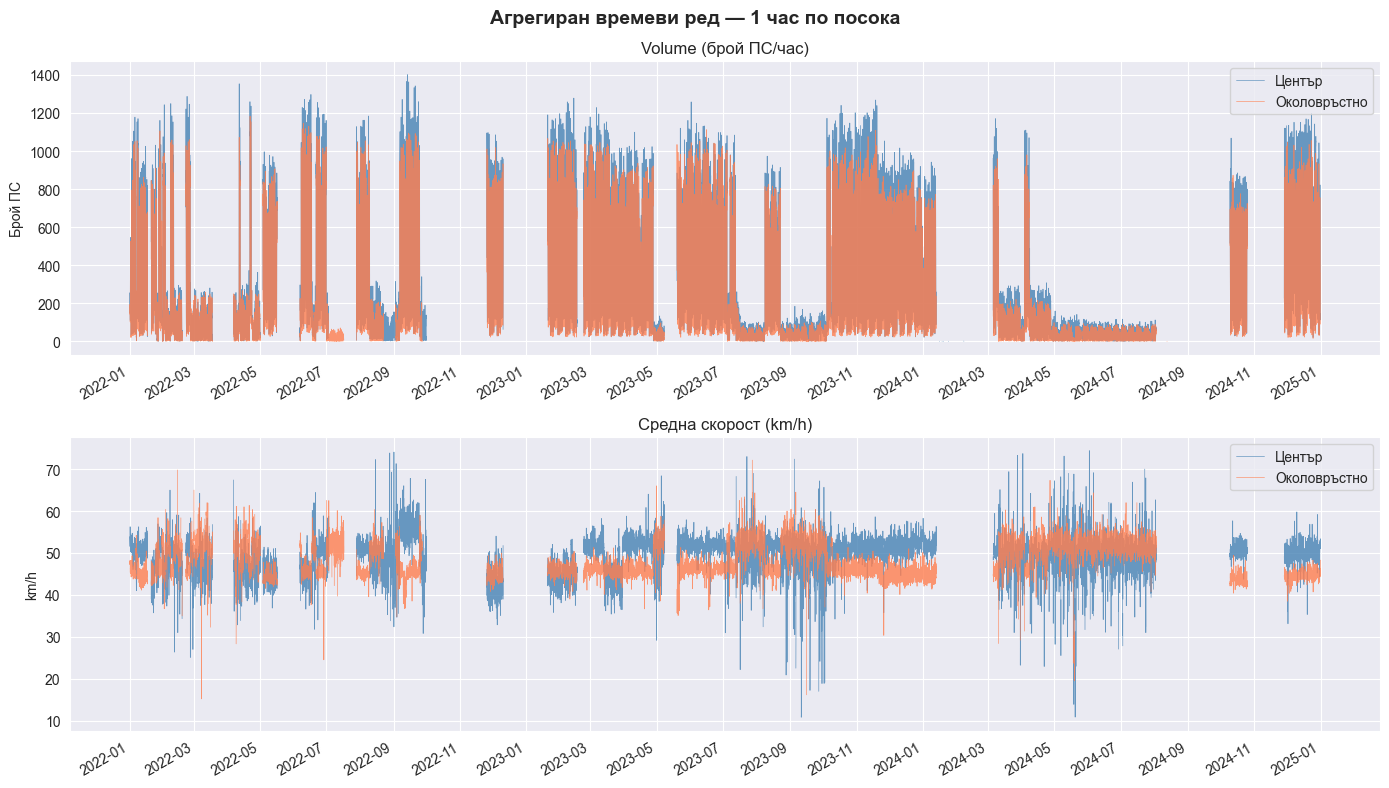


Запазено в data/traffic_aggregated.csv
Редове : 52,608
Колони : ['datetime', 'direction', 'volume', 'avg_speed']


In [10]:
import matplotlib.dates as mdates

# Визуализация на финалния времеви ред
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))
fig.suptitle("Агрегиран времеви ред — 1 час по посока", 
             fontsize=14, fontweight="bold")

for direction, color in [("Център", "steelblue"), ("Околовръстно", "coral")]:
    sub = hourly_full[hourly_full["direction"] == direction]
    ax1.plot(sub["datetime"], sub["volume"], 
             color=color, linewidth=0.5, alpha=0.8, label=direction)
    ax2.plot(sub["datetime"], sub["avg_speed"],
             color=color, linewidth=0.5, alpha=0.8, label=direction)

ax1.set_title("Volume (брой ПС/час)")
ax1.set_ylabel("Брой ПС")
ax1.legend()

ax2.set_title("Средна скорост (km/h)")
ax2.set_ylabel("km/h")
ax2.legend()

for ax in [ax1, ax2]:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("aggregated_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

# Запазване
hourly_full.to_csv("data/traffic_aggregated.csv", index=False)
print(f"\nЗапазено в data/traffic_aggregated.csv")
print(f"Редове : {len(hourly_full):,}")
print(f"Колони : {list(hourly_full.columns)}")